## MSH模型构建

In [1]:
from dataclasses import dataclass
from pathlib import Path
import argparse
import json
import numpy as np
from scipy.integrate import solve_ivp

@dataclass
class Model:
    omega: np.ndarray
    epsilon: np.ndarray
    gamma: np.ndarray
    shifts: np.ndarray
    ground_shift: np.ndarray
    kBT: float
    hbar: float = 1.0
    a0: np.ndarray | None = None
    labels: tuple | None = None
    units: str = "dimensionless"

    def __post_init__(self):

        self.omega = np.array(self.omega, dtype=float, copy=True)
        self.epsilon = np.array(self.epsilon, dtype=float, copy=True)
        self.gamma = np.array(self.gamma, dtype=complex, copy=True)
        self.shifts = np.array(self.shifts, dtype=float, copy=True)
        self.ground_shift = np.array(self.ground_shift, dtype=float, copy=True)

        if self.omega.ndim != 1 or len(self.omega) < 1:
            raise ValueError("omega 必须是非空一维数组。")
        
        if self.epsilon.ndim != 1 or len(self.epsilon) < 1:
            raise ValueError("epsilon 必须是非空一维数组。")
        
        ns, nb = len(self.epsilon), len(self.omega)
        if self.shifts.shape != (ns, nb):
            raise ValueError(f"shifts 应为 {(ns, nb)}，实际 {self.shifts.shape}")
        
        if self.gamma.shape != (ns, ns):
            raise ValueError("gamma 必须是 Nstate x Nstate 矩阵。")
        
        if self.ground_shift.shape != (nb,):
            raise ValueError("ground_shift 必须是长度 Nmode 的数组。")
        
        for arr in (self.omega, self.epsilon, self.gamma,
                    self.shifts, self.ground_shift):
            if not np.all(np.isfinite(arr)):
                raise ValueError("模型参数不能含 NaN 或 Inf。")
            
        if not np.isfinite(self.hbar) or self.hbar <= 0:
            raise ValueError("hbar 必须为正有限值。")
        
        if not np.isfinite(self.kBT) or self.kBT < 0:
            raise ValueError("kBT 必须是非负有限值。")
        
        if np.any(self.omega <= 0):
            raise ValueError("所有 omega 必须为正。")
        
        if not np.allclose(self.gamma, self.gamma.conj().T,
                           rtol=1e-12, atol=1e-14):
            raise ValueError("gamma 必须厄米；不能静默对称化。")
        
        if np.any(np.diag(self.gamma) != 0):
            raise ValueError("gamma 主对角必须为零，对角能量放入 epsilon。")
        
        if self.a0 is None:
            self.a0 = np.zeros(ns, dtype=complex)
            self.a0[0] = 1.0
        else:
            self.a0 = np.array(self.a0, dtype=complex, copy=True)

        if self.a0.shape != (ns,) or not np.all(np.isfinite(self.a0)):
            raise ValueError("a0 形状或数值错误。")
        
        if not np.isclose(np.vdot(self.a0, self.a0).real, 1.0,
                          rtol=0.0, atol=1e-12):
            raise ValueError("请提供归一化的电子初态；程序不会自动归一化。")
        
        if self.labels is None:
            self.labels = tuple(f"state {n+1}" for n in range(ns))
        else:
            self.labels = tuple(str(x) for x in self.labels)
            
        if len(self.labels) != ns:
            raise ValueError("labels 数量必须等于 Nstate。")

    @property
    def ns(self):
        return len(self.epsilon)

    @property
    def nb(self):
        return len(self.omega)

    
def demo_model(name):
    if name == "two-state":
        return Model(
            omega=[1.0], epsilon=[0.0, 0.0],
            gamma=[[0.0, 0.3], [0.3, 0.0]],
            shifts=[[-1.0], [1.0]], ground_shift=[-1.0], kBT=1.0,
            labels=("state 1", "state 2"),
        )
    return Model(
        omega=[1.0, 0.7], epsilon=[0.0, -0.2, 0.1],
        gamma=[[0, 0.25, 0.10], [0.25, 0, -0.15], [0.10, -0.15, 0]],
        shifts=[[-1.0, 0.0], [1.0, 0.5], [0.2, -0.8]],
        ground_shift=[-1.0, 0.0], kBT=1.0,
        labels=("demo 1", "demo 2", "demo 3"),
    )


def pack_state(R, P, a):
    """通用顺序：[全部 R，全部 P，全部 Re(a)，全部 Im(a)]正向拼接，把物理变量打包成求解器能识别的实数组"""
    return np.concatenate((R, P, a.real, a.imag))


def unpack_state(y, m):
    """支持单个状态 [D] 和求解结果 [D,Ntime]反向拆分，从一维实数组还原出(R, P,a(自动把实部虚部合并回复数振幅)"""
    b, s = m.nb, m.ns
    R = y[:b]
    P = y[b:2*b]
    a = y[2*b:2*b+s] + 1j*y[2*b+s:2*b+2*s]
    return R, P, a


def potential_and_gradient(R, m):
    """
    `R` 的形状：`(nb,)`
    `R[None, :]`：在前面新增一个维度，变成 `(1, nb)`，广播用
    `m.shifts`：形状 `(ns, nb)`广播相减：
    """
    displacement = R[None, :] - m.shifts       # [Nstate,Nmode]
    gradient = displacement * m.omega[None, :]**2
    V = m.epsilon + 0.5*np.sum(displacement*gradient, axis=1)
    return V, gradient


def rhs(t, y, m):
    R, P, a = unpack_state(y, m)
    V, gradient = potential_and_gradient(R, m)
    da = -1j*(V*a + m.gamma @ a) / m.hbar
    dP = -(np.abs(a)**2 @ gradient)
    return pack_state(P, dP, da)


def sample_initial_conditions(m, ntraj, seed):
    factor = (np.ones(m.nb) if m.kBT == 0 else
              1.0/np.tanh(m.hbar*m.omega/(2*m.kBT)))
    sigma_R = np.sqrt(m.hbar/(2*m.omega)*factor)
    sigma_P = np.sqrt(m.hbar*m.omega/2*factor)
    # 独立随机流；固定模式数与 seed 时，增加轨迹数保留原有样本。
    sr, sp = np.random.SeedSequence(seed).spawn(2)
    R0 = np.random.default_rng(sr).normal(
        m.ground_shift, sigma_R, size=(ntraj, m.nb))
    P0 = np.random.default_rng(sp).normal(
        0.0, sigma_P, size=(ntraj, m.nb))
    return R0, P0, sigma_R, sigma_P


def reorganization_matrix(m):
    """最后一行/列为初始参考态 G；能量单位与 epsilon 相同。"""
    shifts = np.vstack((m.shifts, m.ground_shift))
    diff = shifts[:, None, :] - shifts[None, :, :]
    return 0.5*np.sum((diff*m.omega)**2, axis=-1)


def energy_components(R, P, a, m):
    """R/P: [Ntime,Nmode]；a: [Ntime,Nstate]。"""
    kin = 0.5*np.sum(P**2, axis=1)
    diag = np.zeros(len(R))
    for n in range(m.ns):
        Vn = m.epsilon[n] + 0.5*np.sum(
            (m.omega*(R-m.shifts[n]))**2, axis=1)
        diag += np.abs(a[:, n])**2*Vn
    coupling = np.einsum("ti,ij,tj->t", a.conj(), m.gamma, a).real
    return np.column_stack((kin, diag, coupling))


def simulate(m, ntraj=200, seed=2026, t_end=30.0, ntime=601,
            rtol=1e-9, atol=1e-11, max_step=0.05, progress=True):
    if ntraj < 2 or ntime < 2 or not np.isfinite(t_end) or t_end <= 0:
        raise ValueError("ntraj、ntime 至少为 2，t_end 必须为正有限值。")
    if any(not np.isfinite(x) or x <= 0 for x in (rtol, atol, max_step)):
        raise ValueError("rtol、atol、max_step 必须为正有限值。")

    times = np.linspace(0.0, t_end, ntime)
    R0, P0, sigma_R, sigma_P = sample_initial_conditions(m, ntraj, seed)

    R_samples = np.empty((ntraj, ntime, m.nb))
    P_samples = np.empty_like(R_samples)
    a_samples = np.empty((ntraj, ntime, m.ns), complex)
    parts = np.empty((ntraj, ntime, 3))

    for ell in range(ntraj):
        y0 = pack_state(R0[ell], P0[ell], m.a0)
        sol = solve_ivp(
            rhs, (0.0, t_end), y0, args=(m,), t_eval=times,
            method="DOP853", rtol=rtol, atol=atol, max_step=max_step,
        )
        if not sol.success or not np.all(np.isfinite(sol.y)):
            raise RuntimeError(f"Trajectory {ell} failed: {sol.message}")

        R, P, a = unpack_state(sol.y, m)
        R_samples[ell], P_samples[ell], a_samples[ell] = R.T, P.T, a.T
        parts[ell] = energy_components(R.T, P.T, a.T, m)

        if progress and ((ell+1) % max(1, ntraj//10) == 0 or ell+1 == ntraj):
            print(f"Completed {ell+1}/{ntraj}", flush=True)

    # 系综平均密度矩阵、布居、标准误
    rho_avg = np.einsum("lti,ltj->tij", a_samples, a_samples.conj(), optimize=True)/ntraj
    pops = np.abs(a_samples)**2
    pop_avg = rho_avg.diagonal(axis1=1, axis2=2).real
    pop_sem = pops.std(axis=0, ddof=1)/np.sqrt(ntraj)
    energy = parts.sum(axis=2)
    drift = energy - energy[:, :1]

    return dict(
        times=times, R0=R0, P0=P0, sigma_R=sigma_R, sigma_P=sigma_P,
        R_samples=R_samples, P_samples=P_samples, a_samples=a_samples,
        rho_avg=rho_avg, pop_avg=pop_avg, pop_sem=pop_sem,
        energy_drift=drift, energy_parts=parts,
        reorganization=reorganization_matrix(m),
    )


In [ ]:
# Notebook里面直接这样跑，绕开argparse
#m = demo_model("two-state")
## 一个非常简单的MSH模型示例
m = Model(
    # 一个参考频率，扩展为两个同频方向
    omega=[1.0, 1.0], epsilon=[0.0, -0.2, 0.1],
    gamma=[[0.0,  0.25,  0.10], [0.25, 0.0,  -0.15], [0.10, -0.15, 0.0],],
    shifts=[
        [0.0, 0.0],   # 态 1
        [1.0, 0.0],   # 态 2
        [0.6, 1.2],   # 态 3
    ],

    # 在态 1 势阱上准备核热态
    ground_shift=[0.0, 0.0],
    kBT=1.0,

    labels=("state 1", "state 2", "state 3"),
)
res = simulate(m, ntraj=200, seed=2026, t_end=30.0, ntime=601, rtol=1e-9, atol=1e-11, max_step=0.05)


Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200


In [3]:
print(res.keys())

dict_keys(['times', 'R0', 'P0', 'sigma_R', 'sigma_P', 'R_samples', 'P_samples', 'a_samples', 'rho_avg', 'pop_avg', 'pop_sem', 'energy_drift', 'energy_parts', 'reorganization'])


## 绘制布居动力学（带误差带，学术图风格）

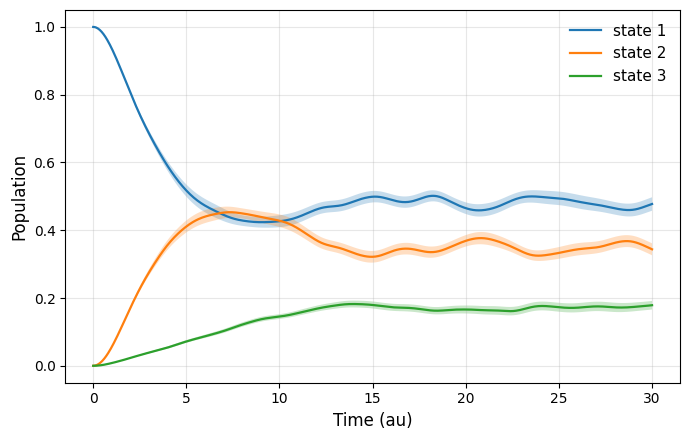

In [4]:
import matplotlib.pyplot as plt

times = res["times"]
pop_avg = res["pop_avg"]
pop_sem = res["pop_sem"]
labels = m.labels

plt.figure(figsize=(7,4.5))
for i in range(m.ns):
    plt.plot(times, pop_avg[:,i], label=labels[i], linewidth=1.6)
    plt.fill_between(
        times,
        pop_avg[:,i] - pop_sem[:,i],
        pop_avg[:,i] + pop_sem[:,i],
        alpha=0.25
    )
plt.xlabel("Time (au)", fontsize=12)
plt.ylabel("Population", fontsize=12)
plt.legend(frameon=False, fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 能量漂移（守恒校验，Ehrenfest 最重要的检查）

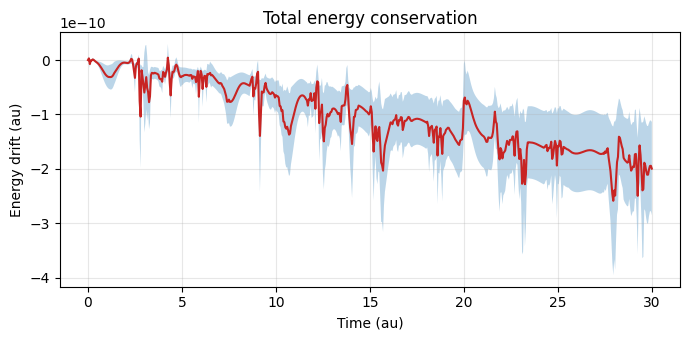

In [5]:
energy_drift = res["energy_drift"]
drift_mean = energy_drift.mean(axis=0)
drift_sem = energy_drift.std(axis=0, ddof=1) / np.sqrt(energy_drift.shape[0])

plt.figure(figsize=(7,3.5))
plt.plot(times, drift_mean, c="#c82423", lw=1.5)
plt.fill_between(times, drift_mean - drift_sem, drift_mean + drift_sem, alpha=0.3)
plt.xlabel("Time (au)")
plt.ylabel("Energy drift (au)")
plt.title("Total energy conservation")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 核坐标的系综平均（核位置随时间演化）

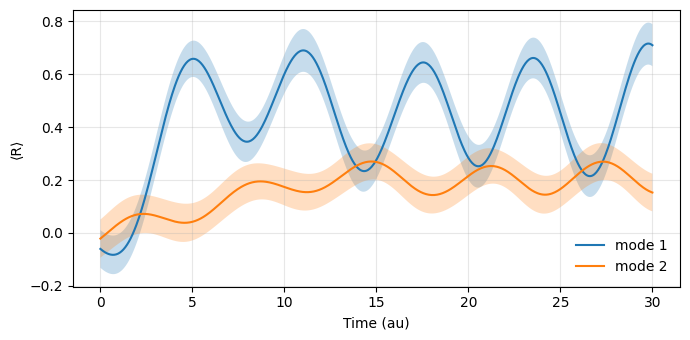

In [6]:
R_samples = res["R_samples"]
R_mean = R_samples.mean(axis=0)  # (ntime, nb)
R_sem = R_samples.std(axis=0, ddof=1) / np.sqrt(R_samples.shape[0])

plt.figure(figsize=(7,3.5))
for mode in range(m.nb):
    plt.plot(times, R_mean[:, mode], label=f"mode {mode+1}", lw=1.5)
    plt.fill_between(times, R_mean[:,mode]-R_sem[:,mode], R_mean[:,mode]+R_sem[:,mode], alpha=0.25)
plt.xlabel("Time (au)")
plt.ylabel("⟨R⟩")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## MSH：sun真实例子

In [1]:
#!/usr/bin/env python3
"""简化学习版：CPC60 MSH 三态Ehrenfest，去掉全部校验与审计"""
from pathlib import Path
import csv
import numpy as np

# 单位转换常数
HARTREE_EV = 27.211386245988
AU_TIME_FS = 0.024188843265857
KB_HARTREE_K = 3.166811563e-6

# 论文参数表
TABLE = {
    2: dict(
        epsilon_ev=[0.0, -0.268, -0.779],
        gamma_ev=[[0, 0.088, 0.00011], [0.088, 0, 0.00012],
                   [0.00011, 0.00012, 0]],
        lambda_ev=[[0,.311,1.507,.127], [.311,0,1.316,.559],
                   [1.507,1.316,0,1.699], [.127,.559,1.134,0]],
    ),
    3: dict(
        epsilon_ev=[0.0, -0.828, -0.640],
        gamma_ev=[[0,-0.015,0.0072], [-0.015,0,-0.029],
                   [0.0072,-0.029,0]],
        lambda_ev=[[0,.340,.492,.150], [.340,0,.041,.910],
                   [.492,.041,0,1.134], [.150,.910,1.134,0]],
    ),
}

def load_csv(path):
    """精简版：读取频率与位移，去掉表头、行数、索引、有限值检查"""
    expected = ["j", "omega_j/au"] + [
        f"Sj_{a}{n}" for n in range(1, 5) for a in range(1, 4)]
    with Path(path).open(encoding="utf-8-sig", newline="") as f:
        reader = csv.DictReader(f)
        rows = list(reader)
    w = np.array([float(r["omega_j/au"]) for r in rows])
    s = np.array([
        [[float(r[f"Sj_{a}{n}"]) for a in range(1, 4)] for r in rows]
        for n in range(1, 5)])
    return w, s


def build_model(path, conf=3, temperature_K=300.0):
    
    w, s = load_csv(path)
    table = TABLE[conf]

    m = Model(
        omega=np.repeat(w, 3),
        epsilon=np.array(table["epsilon_ev"])/HARTREE_EV,
        gamma=np.array(table["gamma_ev"])/HARTREE_EV,
        shifts=s[:3].reshape(3, -1),
        ground_shift=s[3].reshape(-1),
        kBT=KB_HARTREE_K*temperature_K,
        hbar=1.0, labels=("pi-pi*", "CT1", "CT2"),
    )
    # 线性耦合展开（给EH-TEMPO/HEOM用）
    d = m.shifts - m.ground_shift
    c = -(m.omega**2) * d
    vertical = m.epsilon + 0.5 * np.sum((m.omega*d)**2, axis=1)

    return m, d, c, vertical


In [2]:
from multistate_ehrenfest import Model, simulate

# 使用构象 3 对应的原始参数文件
csv_path = "/home/xiaoyu/HelloWorld/cpc60_msh/data/MSH-4State-conf3-param.csv"

m, d, c, vertical = build_model(
    csv_path,
    conf=3,
    temperature_K=300.0,
)

# 时间设置：输入以 fs 表达，传给传播器前转换成原子时间
t_end_fs = 20.0
output_dt_fs = 0.1
max_step_fs = 0.1

res = simulate(
    m,
    ntraj=8,
    seed=2026,
    t_end=t_end_fs / AU_TIME_FS,
    ntime=int(round(t_end_fs / output_dt_fs)) + 1,
    max_step=max_step_fs / AU_TIME_FS,
    rtol=1e-11,
    atol=1e-13,
)

# 后处理和作图时使用 fs
times_fs = res["times"] * AU_TIME_FS
populations = res["pop_avg"]

Completed 20/200
Completed 40/200
Completed 60/200
Completed 80/200
Completed 100/200
Completed 120/200
Completed 140/200
Completed 160/200
Completed 180/200
Completed 200/200
Completed 1/8
Completed 2/8
Completed 3/8
Completed 4/8
Completed 5/8
Completed 6/8
Completed 7/8
Completed 8/8
